# Experiment 13: Implementing Responsible AI and Bias Mitigation Techniques

**Aim:** Detect, measure and mitigate bias in a machine-learning model, and apply responsible-AI practices that also
matter for generative AI: fairness metrics, mitigation (pre-, in- and post-processing), explainability, privacy and
output safety filtering, documented in a model card.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate, false_positive_rate,
                               demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference)
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds
from fairlearn.postprocessing import ThresholdOptimizer
rng = np.random.default_rng(13)
print("setup complete")

setup complete


## 1. A dataset with historical bias
We simulate a hiring data set. The true qualification of candidates is identically distributed in both groups, but the
*historical decisions* (the labels) penalise group 1 (e.g. women), and a "career_gap" feature acts as a **proxy** for the
protected attribute. This mirrors how real data encodes past discrimination.

   experience  education  skill_test  career_gap  sex  hired
0    9.298910   0.433677    0.602832    0.802575    1      1
1    8.081919  -0.051605    1.877167    0.847521    1      0
2    3.109263   0.472814   -0.343363    2.210135    1      1
3    1.567772  -1.080862   -0.763477    0.000000    0      0
4    2.992095  -0.833697    0.654071    0.000000    0      1 

group sizes: {0: 4433, 1: 3567}
mean merit by group   : {0: 1.478, 1: 1.513} (equal by construction)
historical hire rate  : {0: 0.496, 1: 0.263}
correlation(career_gap, sex) = 0.72


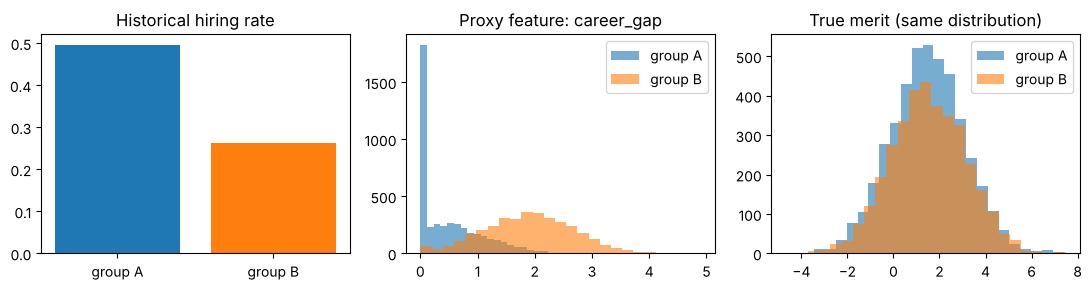

In [2]:
n = 8000
sex = rng.binomial(1, 0.45, n)                                  # protected attribute: 0 = group A, 1 = group B
experience = np.clip(rng.normal(6, 3, n), 0, None)
education = rng.normal(0, 1, n)
skill_test = rng.normal(0, 1, n)
career_gap = np.clip(rng.normal(0.3 + 1.6 * sex, 0.8, n), 0, None)   # proxy: strongly correlated with group
merit = 0.25 * experience + 0.9 * education + 1.1 * skill_test          # true qualification (same in both groups)
logit = (merit - merit.mean()) / merit.std() * 1.6 - 1.0 * sex - 0.4 * career_gap + 0.2   # biased historical decision
hired = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
df = pd.DataFrame(dict(experience=experience, education=education, skill_test=skill_test, career_gap=career_gap, sex=sex, hired=hired))
print(df.head(), "\n")
print("group sizes:", df.sex.value_counts().to_dict())
print("mean merit by group   :", df.assign(m=merit).groupby("sex").m.mean().round(3).to_dict(), "(equal by construction)")
print("historical hire rate  :", df.groupby("sex").hired.mean().round(3).to_dict())
print("correlation(career_gap, sex) = %.2f" % df.career_gap.corr(df.sex))
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].bar(["group A", "group B"], df.groupby("sex").hired.mean(), color=["tab:blue", "tab:orange"]); ax[0].set_title("Historical hiring rate")
for g, c in ((0, "tab:blue"), (1, "tab:orange")):
    ax[1].hist(df[df.sex == g].career_gap, bins=25, alpha=.6, color=c, label=f"group {'AB'[g]}")
    ax[2].hist(merit[sex == g], bins=25, alpha=.6, color=c, label=f"group {'AB'[g]}")
ax[1].set_title("Proxy feature: career_gap"); ax[1].legend(); ax[2].set_title("True merit (same distribution)"); ax[2].legend()
plt.tight_layout(); plt.show()

In [3]:
features = ["experience", "education", "skill_test", "career_gap"]
Xtr, Xte, ytr, yte, str_, ste = train_test_split(df[features + ["sex"]], df.hired, df.sex, test_size=0.3, random_state=0, stratify=df.hired)
print("train:", Xtr.shape, "test:", Xte.shape)

train: (5600, 5) test: (2400, 5)


## 2. Measuring bias in a baseline model

In [4]:
def report(y_true, y_pred, sens, name):
    mf = MetricFrame(metrics={"accuracy": accuracy_score, "selection_rate": selection_rate, "TPR": true_positive_rate, "FPR": false_positive_rate},
                     y_true=y_true, y_pred=y_pred, sensitive_features=sens)
    dp = demographic_parity_difference(y_true, y_pred, sensitive_features=sens)
    di = demographic_parity_ratio(y_true, y_pred, sensitive_features=sens)
    eo = equalized_odds_difference(y_true, y_pred, sensitive_features=sens)
    tpr_gap = mf.by_group["TPR"].max() - mf.by_group["TPR"].min()
    return dict(model=name, accuracy=accuracy_score(y_true, y_pred), dp_diff=dp, disparate_impact=di, eq_odds_diff=eo, tpr_gap=tpr_gap), mf
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr[features + ["sex"]], ytr)
res, mf = [], None
r, mf = report(yte, base.predict(Xte[features + ["sex"]]), ste, "baseline (uses sex)"); res.append(r)
print("Per-group metrics of the baseline model:\n", mf.by_group.round(3), "\n")
print("Demographic-parity difference : %.3f (0 = fair)" % r["dp_diff"])
print("Disparate-impact ratio        : %.3f (4/5 rule requires >= 0.80)" % r["disparate_impact"])
print("Equalised-odds difference     : %.3f" % r["eq_odds_diff"])

Per-group metrics of the baseline model:
      accuracy  selection_rate    TPR    FPR
sex                                        
0       0.729           0.479  0.715  0.258
1       0.794           0.177  0.448  0.071 

Demographic-parity difference : 0.302 (0 = fair)
Disparate-impact ratio        : 0.369 (4/5 rule requires >= 0.80)
Equalised-odds difference     : 0.267


## 3. Bias mitigation
1. **Fairness through unawareness** - drop the protected attribute (does it help when proxies exist?).
2. **Pre-processing: reweighing** - give each (group, label) cell the weight $w=\frac{P(g)P(y)}{P(g,y)}$ so that group and label become statistically independent.
3. **In-processing: constrained optimisation** - `ExponentiatedGradient` with a demographic-parity / equalised-odds constraint.
4. **Post-processing: group-specific thresholds** - `ThresholdOptimizer` adjusts decision thresholds per group.

In [5]:
Xf_tr, Xf_te = Xtr[features], Xte[features]
scaler = StandardScaler().fit(Xf_tr); Xs_tr, Xs_te = scaler.transform(Xf_tr), scaler.transform(Xf_te)   # ExponentiatedGradient needs a plain estimator
# 1. unawareness
m1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xf_tr, ytr)
r, _ = report(yte, m1.predict(Xf_te), ste, "1 unawareness (drop sex)"); res.append(r)
# 2. reweighing
w = np.ones(len(ytr))
for g in (0, 1):
    for y in (0, 1):
        cell = (str_.values == g) & (ytr.values == y)
        w[cell] = (str_.values == g).mean() * (ytr.values == y).mean() / cell.mean()
print("reweighing weights:", {f"group {'AB'[g]}, hired={y}": round(float(w[(str_.values == g) & (ytr.values == y)][0]), 3) for g in (0, 1) for y in (0, 1)})
m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
m2.fit(Xtr[features + ["sex"]], ytr, logisticregression__sample_weight=w)
r, _ = report(yte, m2.predict(Xte[features + ["sex"]]), ste, "2 reweighing (pre)"); res.append(r)
# 3. in-processing
for nm, cons in (("3a exp. gradient: DP", DemographicParity()), ("3b exp. gradient: EO", EqualizedOdds())):
    eg = ExponentiatedGradient(LogisticRegression(max_iter=1000), constraints=cons, eps=0.02)
    eg.fit(Xs_tr, ytr, sensitive_features=str_)
    r, _ = report(yte, eg.predict(Xs_te), ste, nm + " (in)"); res.append(r)
# 4. post-processing
for nm, cons in (("4a threshold opt: DP", "demographic_parity"), ("4b threshold opt: EO", "equalized_odds")):
    to = ThresholdOptimizer(estimator=make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xf_tr, ytr),
                            constraints=cons, prefit=True, predict_method="predict_proba")
    to.fit(Xf_tr, ytr, sensitive_features=str_)
    r, _ = report(yte, to.predict(Xf_te, sensitive_features=ste, random_state=0), ste, nm + " (post)"); res.append(r)
table = pd.DataFrame(res).set_index("model").round(3)
print("\n" + table.to_string())

reweighing weights: {'group A, hired=0': 1.22, 'group A, hired=1': 0.782, 'group B, hired=0': 0.817, 'group B, hired=1': 1.531}



                             accuracy  dp_diff  disparate_impact  eq_odds_diff  tpr_gap
model                                                                                  
baseline (uses sex)             0.758    0.302             0.369         0.267    0.267
1 unawareness (drop sex)        0.760    0.202             0.538         0.142    0.142
2 reweighing (pre)              0.751    0.077             0.795         0.027    0.005
3a exp. gradient: DP (in)       0.741    0.004             0.988         0.113    0.113
3b exp. gradient: EO (in)       0.752    0.107             0.727         0.042    0.042
4a threshold opt: DP (post)     0.733    0.007             0.976         0.119    0.119
4b threshold opt: EO (post)     0.744    0.103             0.755         0.041    0.041


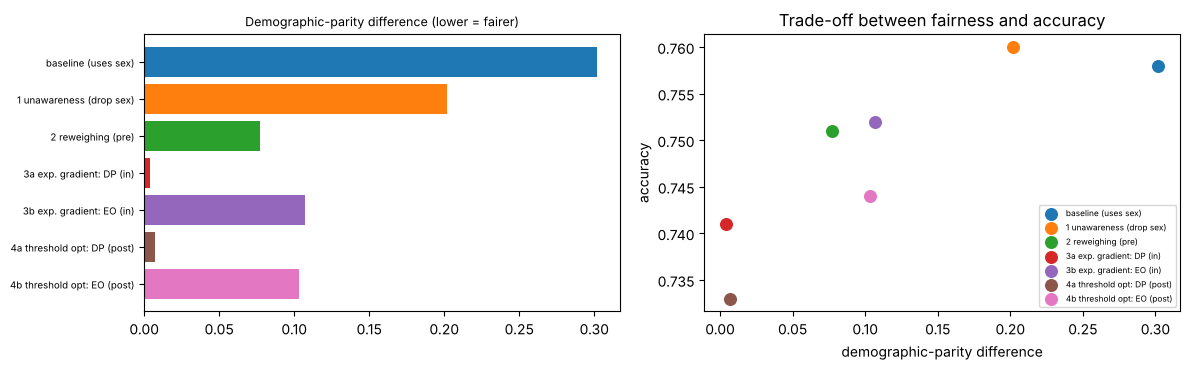

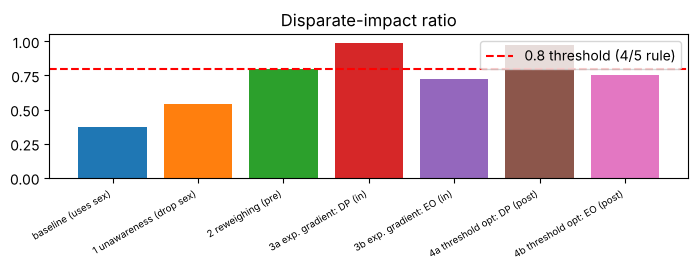

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
t = table.reset_index()
cols = plt.cm.tab10(np.arange(len(t)))
ax[0].barh(t.model, t.dp_diff, color=cols); ax[0].invert_yaxis(); ax[0].set_title("Demographic-parity difference (lower = fairer)", fontsize=9)
ax[0].tick_params(axis="y", labelsize=7)
for i, row in t.iterrows(): ax[1].scatter(row.dp_diff, row.accuracy, s=70, color=cols[i], label=row.model)
ax[1].set(xlabel="demographic-parity difference", ylabel="accuracy", title="Trade-off between fairness and accuracy"); ax[1].legend(fontsize=6, loc="best")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(t.model, t.disparate_impact, color=cols); ax.axhline(0.8, c="r", ls="--", label="0.8 threshold (4/5 rule)")
ax.set_ylim(0, 1.05); ax.set_title("Disparate-impact ratio"); ax.legend(); plt.xticks(rotation=30, ha="right", fontsize=7); plt.tight_layout(); plt.show()

## 4. Explainability, privacy, safety and documentation

Gradient-boosting model WITHOUT the sex column - permutation importance (drop in accuracy):
experience    0.0424
career_gap    0.0497
education     0.0677
skill_test    0.0975

Even without 'sex', DP difference of the boosted model = 0.178 -> bias flows in through the proxy 'career_gap'.


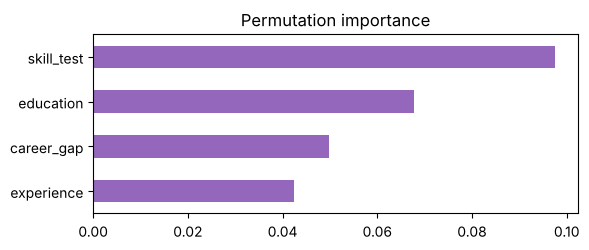

In [7]:
gb = GradientBoostingClassifier(random_state=0).fit(Xf_tr, ytr)
pi = permutation_importance(gb, Xf_te, yte, n_repeats=8, random_state=0)
imp = pd.Series(pi.importances_mean, index=features).sort_values()
print("Gradient-boosting model WITHOUT the sex column - permutation importance (drop in accuracy):")
print(imp.round(4).to_string())
rep = report(yte, gb.predict(Xf_te), ste, "gb")[0]
print("\nEven without 'sex', DP difference of the boosted model = %.3f -> bias flows in through the proxy 'career_gap'." % rep["dp_diff"])
fig, ax = plt.subplots(figsize=(6, 2.6)); imp.plot.barh(ax=ax, color="tab:purple"); ax.set_title("Permutation importance"); plt.tight_layout(); plt.show()

True hiring rate of group B in the training data: 0.2562
epsilon = 0.01 : mean absolute error of the private estimate = 0.0425
epsilon = 0.1  : mean absolute error of the private estimate = 0.0041
epsilon = 1.0  : mean absolute error of the private estimate = 0.0004


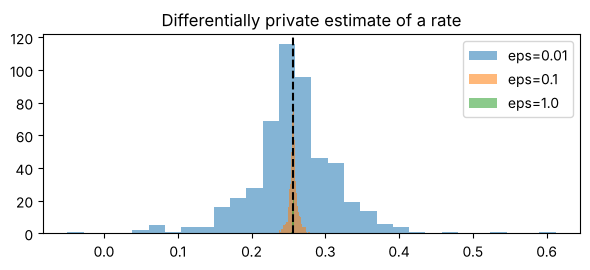

In [8]:
def dp_rate(group_mask, eps):
    cnt = int((ytr.values[group_mask] == 1).sum()); size = int(group_mask.sum())
    noisy_cnt = cnt + rng.laplace(0, 1 / eps)            # sensitivity of a count = 1
    return noisy_cnt / size
true_rate = ytr.values[str_.values == 1].mean()
print("True hiring rate of group B in the training data: %.4f" % true_rate)
fig, ax = plt.subplots(figsize=(6, 2.8))
for eps in (0.01, 0.1, 1.0):
    est = [dp_rate(str_.values == 1, eps) for _ in range(500)]
    err = np.mean(np.abs(np.array(est) - true_rate))
    print(f"epsilon = {eps:<5}: mean absolute error of the private estimate = {err:.4f}")
    ax.hist(est, bins=30, alpha=.55, label=f"eps={eps}")
ax.axvline(true_rate, c="k", ls="--"); ax.set_title("Differentially private estimate of a rate"); ax.legend(); plt.tight_layout(); plt.show()

In [9]:
BLOCK = {"idiot", "stupid", "hate", "kill"}
PATTERNS = {"EMAIL": r"[\w.+-]+@[\w-]+\.[\w.]+", "PHONE": r"\b(?:\+?\d{1,3}[ -]?)?\d{10}\b", "AADHAAR-LIKE": r"\b\d{4} \d{4} \d{4}\b"}
def safety_filter(text):
    flags = []
    for name, pat in PATTERNS.items():
        if re.search(pat, text): flags.append(name); text = re.sub(pat, f"[{name} REMOVED]", text)
    hits = [w for w in re.findall(r"\w+", text.lower()) if w in BLOCK]
    if hits: flags.append("TOXICITY:" + ",".join(sorted(set(hits)))); text = "[BLOCKED: unsafe content]"
    return text, flags
samples = ["Contact the author at jane.doe@example.com or 9876543210 for the full report.",
           "You are an idiot and I hate this.", "My id number is 1234 5678 9012.", "The quick brown fox jumps over the lazy dog."]
for s in samples:
    out, flags = safety_filter(s)
    print(f"INPUT : {s}\nOUTPUT: {out}\nFLAGS : {flags or 'none'}\n")

INPUT : Contact the author at jane.doe@example.com or 9876543210 for the full report.
OUTPUT: Contact the author at [EMAIL REMOVED] or [PHONE REMOVED] for the full report.
FLAGS : ['EMAIL', 'PHONE']

INPUT : You are an idiot and I hate this.
OUTPUT: [BLOCKED: unsafe content]
FLAGS : ['TOXICITY:hate,idiot']

INPUT : My id number is 1234 5678 9012.
OUTPUT: My id number is [AADHAAR-LIKE REMOVED].
FLAGS : ['AADHAAR-LIKE']

INPUT : The quick brown fox jumps over the lazy dog.
OUTPUT: The quick brown fox jumps over the lazy dog.
FLAGS : none



In [10]:
base_r, best = table.iloc[0], table["dp_diff"].idxmin()
card = f"""MODEL CARD - Hiring-score classifier (educational example)
Intended use     : demonstrate fairness auditing; NOT for real hiring decisions.
Training data    : 8,000 synthetic candidates, groups A/B (55%/45%), labels contain simulated historical bias.
Model            : logistic regression, 4 numeric features (+ protected attribute in baseline).
Baseline results : accuracy {base_r.accuracy:.3f}, DP difference {base_r.dp_diff:.3f}, disparate impact {base_r.disparate_impact:.3f}.
Best fairness    : '{best}' -> DP difference {table.loc[best, 'dp_diff']:.3f}, accuracy {table.loc[best, 'accuracy']:.3f}.
Known limitations: proxy feature (career_gap) leaks group membership; fairness metrics conflict with each other;
                   synthetic data cannot capture real-world bias.
Mitigations      : reweighing, constrained optimisation, threshold optimisation; PII/toxicity output filter.
Monitoring       : re-audit selection rates per group on every model update."""
print(card)

MODEL CARD - Hiring-score classifier (educational example)
Intended use     : demonstrate fairness auditing; NOT for real hiring decisions.
Training data    : 8,000 synthetic candidates, groups A/B (55%/45%), labels contain simulated historical bias.
Model            : logistic regression, 4 numeric features (+ protected attribute in baseline).
Baseline results : accuracy 0.758, DP difference 0.302, disparate impact 0.369.
Best fairness    : '3a exp. gradient: DP (in)' -> DP difference 0.004, accuracy 0.741.
Known limitations: proxy feature (career_gap) leaks group membership; fairness metrics conflict with each other;
                   synthetic data cannot capture real-world bias.
Mitigations      : reweighing, constrained optimisation, threshold optimisation; PII/toxicity output filter.
Monitoring       : re-audit selection rates per group on every model update.
